# LeetCode #295: Find Median from Data Stream

https://leetcode.com/problems/find-median-from-data-stream/

## Three ways to solve it

| Approach | addNum | findMedian | What that means in practice |
| :--- | :--- | :--- | :--- |
| **Sorted list, insert in place** | $O(n)$ | $O(1)$ | Finding the spot is fast, but inserting shifts everything after it. |
| **Balanced search tree with counts** | $O(\log n)$ | $O(\log n)$ | Fast both ways, but a lot of machinery to write. |
| **Two heaps, one per half ★** | $O(\log n)$ | $O(1)$ | A few heap operations per number; the median is always sitting on top. |

`n` is how many numbers have been added (up to 50,000). $O(n)$ per add means the work grows with
everything stored: 50,000 adds into a sorted list can shift around a billion items in total.
$O(\log n)$ means about $\log_2 n$ steps, roughly 16 at 50,000 numbers. $O(1)$ means a fixed couple of
steps however many numbers there are.

The **median** is the middle value once the numbers are sorted; with an even count it's the average of
the two middle values. A **heap** hands you its top item (the smallest, or for a *max-heap* the largest)
in one step, and adds or removes an item in about $\log_2 n$ steps.

## Understanding the methods

### Sorted list, insert in place

Keep every number in order. Binary search finds where a new number goes, but inserting it means moving
every later number one slot, which is $O(n)$ per add.

### Balanced search tree with counts

A self-balancing tree where each node knows its subtree size can insert and find the middle element in
$O(\log n)$ each. Correct and fast, but long and fiddly to write in an interview.

### Optimal: Two heaps, one per half ★ (the one coded below)

The median only depends on the middle, so split the numbers into a lower half and an upper half. Keep
the lower half in a max-heap (its top is the largest of the small numbers) and the upper half in a
min-heap (its top is the smallest of the big ones). Keep the halves the same size, or the lower one
bigger by one. Then the median is the lower top, or the average of the two tops.

**Why this beats the alternatives:** an add is a few heap operations instead of shifting a list, and
the median is read straight off the tops, with far less code than a balanced tree.

**Constraints:**
* `-10^5 <= num <= 10^5`
* There will be at least one element in the data structure before calling `findMedian`
* At most `5 * 10^4` calls will be made to `addNum` and `findMedian`


## Explain Like I'm a Newbie

### Primer: a heap

A heap is a pile that always keeps one particular item on top. In a **min-heap** it's the smallest; in a
**max-heap** it's the largest. Looking at the top is instant. Adding an item or removing the top costs
about $\log_2 n$ steps, because the heap only reshuffles one path through itself, not the whole pile. It
is *not* fully sorted: you can only see the top. That's all this problem needs.

### What the question is actually asking

Numbers arrive one at a time. At any moment someone can ask for the median of everything so far:
`[1, 2]` has median 1.5, and after a 3 arrives, `[1, 2, 3]` has median 2.

### The one idea you need: you don't need the numbers sorted, only the two in the middle

Picture the numbers split down the middle:

```
lower half          upper half
 1  2   |   3        median: the biggest of the lower half (odd count)
 1  2   |   3  4     median: (biggest lower + smallest upper) / 2
```

So you only ever need two things quickly: the **largest** number in the lower half and the **smallest**
in the upper half. A max-heap gives the first, a min-heap gives the second. Two rules keep it working:

- **Order:** everything in the lower half is ≤ everything in the upper half.
- **Balance:** the halves are the same size, or the lower one has one extra.

### What that means in code

To add a number without breaking the order rule, push it into the lower heap, then move the lower
heap's top across to the upper heap. Whatever crosses is the largest of the lower side, so the order
rule holds. Then fix the balance: if the upper heap is now bigger, move its top back.

Asking for the median is then just a look at the tops: if the lower heap has the extra number, its top
is the answer; if the halves are equal, average the two tops. Neither heap is searched or sorted.

### Mistakes people make the first time

1. **Rebalancing in one direction only.** Put each number in the half it belongs to, and move items
   only when the upper heap grows too big. That passes LeetCode's sample (1, 2, median 1.5, 3, median 2),
   because the stream rises. Add 3 then 2 and it answers 3 instead of 2.5: both numbers piled into the
   lower heap and nothing moved them.
2. **Integer division for the even case.** `(1 + 2) // 2` is 1, not 1.5.
3. **Forgetting the minus sign in Python.** `heapq` only makes min-heaps, so the lower half stores
   negated numbers. Reading its top without flipping the sign back gives −1 instead of 1.

### Things worth knowing

Every number is kept forever, so memory grows with the stream. In C#, Go and Rust the two tops are
added as integers before dividing; that's safe for values up to $10^5$ but would overflow near the 32-bit
limit.


## Talking It Through in an Interview

*Written from the interviewer's chair. This is what I'd want to hear from you, from the moment I show you the problem to the moment the code is on the board.*

---

### The 30-second pitch

> **You:** "The median only depends on the two middle numbers, so I'll split the stream into a lower half in a max-heap and an upper half in a min-heap, with the lower half allowed one extra. To add, I push into the lower heap, move its top across, and move one back if the upper heap got bigger. The median is the lower top, or the average of both tops. Adds are a few heap operations, O(log n); finding the median is O(1). The cost is memory: every number stays forever."

Two heaps, two rules, and an honest cost. I'll spend the rest of the interview checking each one.

---

### I slide the problem across the table

I give you the class with `addNum` and `findMedian` and LeetCode's sequence: add 1, add 2, median, add 3, median.

> **You:** "Will `findMedian` ever be called on an empty structure?"

**"No, there's always at least one number."** That saves a guard and it's a real question, because the code reads both tops.

> **You:** "With an even count, you want the average as a decimal, so 1.5, not 1?"

**"Yes, a float."** That decides the division.

> **You:** "Range of values and number of calls?"

**"Values from −100,000 to 100,000; up to 50,000 calls."** Hold onto the range. It matters once at the end.

---

### Now tell me what's actually hard about it

> **You:** "Keeping everything sorted is the obvious way, and finding the median is then just indexing. The problem is the adds. Inserting into the middle of a list shifts everything after it, so 50,000 adds can be around a billion moves. And I'm paying to keep every number in order when I only ever look at the middle."

> **You:** "If I split the numbers into a lower half and an upper half, I only need the biggest of the lower half and the smallest of the upper half. 'Give me the biggest quickly' is a max-heap; 'give me the smallest quickly' is a min-heap."

The structure fell out of what the question actually reads. That's what I want to hear before the word "heap".

A candidate who knows Python sometimes says "`bisect.insort` would be fine at 50,000". I don't mind that at all, as long as it comes with the honest version:

> **You:** "It would probably pass, because the shifting is one fast block copy. But it's still O(n) per add, so it's the first thing to fall over if the stream gets ten times longer, and in most other languages there's no such shortcut."

---

### Draw the structures before the methods

```
small: max-heap   lower half; top = largest of the small numbers
large: min-heap   upper half; top = smallest of the big numbers

rules:  every number in small <= every number in large
        len(small) == len(large)  or  len(small) == len(large) + 1
```

> **You:** "The first rule makes the two tops the two middle numbers. The second decides which top is the median when the count is odd: I let `small` hold the extra one."

If I ask why `small` and not `large` gets the extra one:

> **You:** "No deep reason. Either works, as long as `addNum` and `findMedian` agree. If `addNum` lets `large` grow bigger but `findMedian` reads `small`'s top for odd counts, it returns the wrong middle. Picking one and writing it next to the rules is how I keep them in sync."

That's honest, and the consistency point is the one that actually bites people.

Every method you write next is just restoring those two rules. If I see `addNum` before these lines, I'll ask what it's supposed to keep true.

---

### Before you touch the methods, tell me the shape and the cost

> **You:** "`addNum` does at most five heap operations: push to `small`, pop `small`'s top, push it to `large`, and maybe pop `large` and push to `small`. Each is O(log n), about 16 steps at 50,000 numbers, so an add is O(log n). `findMedian` reads one or two tops: O(1). Space is O(n), all the numbers."

---

### Now whiteboard it

```
def addNum(self, num):
    heapq.heappush(self.small, -num)
    heapq.heappush(self.large, -heapq.heappop(self.small))
```

> **You:** "The new number might belong in either half, and I don't want to compare it against anything. So it goes through `small` first, and `small`'s largest crosses to `large`. Whatever crosses is at least as big as everything left in `small`, so the order rule can't break."

```
    if len(self.large) > len(self.small):
        heapq.heappush(self.small, -heapq.heappop(self.large))
```

> **You:** "Now `large` may be one too big. Moving its smallest back keeps the order rule and restores the balance. Because every number always passes through both heaps' tops, this one check covers rising streams and falling ones."

That's the sentence I was waiting for. The most common bug here rebalances in one direction only and still passes the sample.

```
def findMedian(self):
    if len(self.small) > len(self.large):
        return -self.small[0]
    return (-self.small[0] + self.large[0]) / 2.0
```

> **You:** "Python's `heapq` only does min-heaps, so `small` stores negatives and I flip the sign when I read it. And `/ 2.0`, not integer division, because you said 1.5."

---

### Walk me through it before you say you're done

> **You:** "Add 1: it goes into `small`, crosses to `large`, then `large` is bigger, so it comes back. `small` = {1}, `large` empty. Add 2: into `small`, 2 crosses. {1} and {2}. Median (1 + 2) / 2 = 1.5. Add 3: into `small`, which now has 3 on top, so 3 crosses; `large` = {2, 3} is bigger, so 2 comes back. {1, 2} and {3}. Median is `small`'s top, 2."

> **You:** "And a falling stream, 3 then 2: 3 ends in `small`. 2 goes into `small`, but 3 is the top, so 3 crosses. {2} and {3}, median 2.5. Correct, and it's the case a one-way rebalance gets wrong."

---

### Then tell me where it breaks, before I ask

> **You:** "For this interface it's optimal: you can't add faster than log n and still read the median instantly. Three honest limits. Memory: every number is kept, which matters for a stream that never ends. Overflow: in C# or Go I add the two tops as ints before dividing; with your range that's at most 200,000, but near the 32-bit limit I'd convert to a 64-bit type first. And removals: if you wanted the median of a sliding window, I'd need to delete old numbers, and heaps can't remove from the middle. That needs lazy deletion or two sorted multisets instead."

> **You:** "If you told me all numbers were between 0 and 100, I'd drop the heaps entirely and keep 101 counters. The median is a walk over at most 101 buckets, which is constant time."

That's the generalisation I like: knowing when the clever structure isn't needed.

And if I push once more, "what if 99% of the numbers are between 0 and 100?":

> **You:** "Same 101 counters, plus a count of how many numbers fell below 0 and how many above 100, and the actual outliers kept in two small heaps or sorted lists. The median is almost always inside the counted range; on the rare occasion it isn't, I look in the outlier store on that side, which only holds about 1% of the numbers."

You don't have to get that one perfect. I'm watching whether you reuse what you just built or start again from nothing.

---

### What would worry me

Rebalancing in one direction only, and trusting it because the sample's stream happens to rise. Integer division in the even case. Sorting a list on every `findMedian`. And writing methods before you've said what the two heaps promise.


## Solutions

All four keep the lower half in a max-heap and the upper half in a min-heap. Each new number passes through the lower heap, its top crosses to the upper heap, and one number moves back if the upper heap got bigger.

### C#

`PriorityQueue` always dequeues the lowest priority, so `small` uses `-num` as the priority to behave like a max-heap.


In [ ]:
public class MedianFinder {
    // Lower half, as a MAX-heap: priority -num makes the largest come out first
    private PriorityQueue<int, int> small = new();  // max-heap (negate)
    // Upper half, as a MIN-heap: its top is the smallest of the big numbers
    private PriorityQueue<int, int> large = new();  // min-heap
    // Rules: everything in small <= everything in large, and
    // small has the same count as large or one more

    public void AddNum(int num) {
        // Pass the new number through small and send small's largest across.
        // Whatever crosses is >= everything left in small, so the order rule holds
        // without comparing num to anything.
        small.Enqueue(num, -num);
        int val = small.Dequeue();
        large.Enqueue(val, val);
        // Restore the size rule. Every number passes through both tops, so this one
        // check is enough for rising and falling streams alike.
        if (large.Count > small.Count) {
            int v = large.Dequeue();
            small.Enqueue(v, -v);
        }
    }

    public double FindMedian() {
        // Odd count: small holds the extra one, and its top is the middle
        if (small.Count > large.Count)
            return small.Peek();
        // Even count: average the two middle numbers. 2.0 keeps the .5
        // (the int sum is safe for values up to 10^5)
        return (small.Peek() + large.Peek()) / 2.0;
    }
}

### Python

`heapq` only provides min-heaps, so `small` stores every number negated: its smallest stored value is the largest real number. Every read and every move between the heaps flips the sign.


In [ ]:
import heapq

class MedianFinder:
    def __init__(self):
        # Lower half, as a MAX-heap. heapq only makes min-heaps, so store -num:
        # the smallest negative is the largest number.
        self.small = []  # max-heap (negated)
        # Upper half, as a MIN-heap: its top is the smallest of the big numbers
        self.large = []  # min-heap
        # Rules: everything in small <= everything in large, and
        # small has the same count as large or one more

    def addNum(self, num: int) -> None:
        # Pass the new number through small and send small's largest across.
        # Whatever crosses is >= everything left in small, so the order rule holds
        # without comparing num to anything.
        heapq.heappush(self.small, -num)
        heapq.heappush(self.large, -heapq.heappop(self.small))
        # Restore the size rule. Every number passes through both tops, so this one
        # check is enough for rising and falling streams alike.
        if len(self.large) > len(self.small):
            heapq.heappush(self.small, -heapq.heappop(self.large))

    def findMedian(self) -> float:
        # Odd count: small holds the extra one, and its top is the middle
        if len(self.small) > len(self.large):
            return -self.small[0]   # flip the sign back
        # Even count: average the two middle numbers; / 2.0 keeps the .5
        return (-self.small[0] + self.large[0]) / 2.0

### Go

The two heap types are identical except for `Less`: `<` gives a min-heap, `>` a max-heap. `heap.Push`/`heap.Pop` are the package functions that keep the order; the methods on the types only grow and shrink the slice.


In [ ]:
import "container/heap"

// Upper half: a MIN-heap (Less uses <)
type MinHeap []int
func (h MinHeap) Len() int           { return len(h) }
func (h MinHeap) Less(i, j int) bool  { return h[i] < h[j] }
func (h MinHeap) Swap(i, j int)       { h[i], h[j] = h[j], h[i] }
func (h *MinHeap) Push(x interface{}) { *h = append(*h, x.(int)) }
func (h *MinHeap) Pop() interface{} {
    old := *h; n := len(old); x := old[n-1]; *h = old[:n-1]; return x
}

// Lower half: a MAX-heap (the only difference: Less uses >)
type MaxHeap []int
func (h MaxHeap) Len() int           { return len(h) }
func (h MaxHeap) Less(i, j int) bool  { return h[i] > h[j] }
func (h MaxHeap) Swap(i, j int)       { h[i], h[j] = h[j], h[i] }
func (h *MaxHeap) Push(x interface{}) { *h = append(*h, x.(int)) }
func (h *MaxHeap) Pop() interface{} {
    old := *h; n := len(old); x := old[n-1]; *h = old[:n-1]; return x
}

// Rules: everything in small <= everything in large, and
// small has the same count as large or one more
type MedianFinder struct {
    small MaxHeap
    large MinHeap
}

func Constructor() MedianFinder {
    return MedianFinder{}
}

func (mf *MedianFinder) AddNum(num int) {
    // Pass the new number through small and send small's largest across.
    // Whatever crosses is >= everything left in small, so the order rule holds.
    heap.Push(&mf.small, num)
    heap.Push(&mf.large, heap.Pop(&mf.small))
    // Restore the size rule; one check covers rising and falling streams
    if mf.large.Len() > mf.small.Len() {
        heap.Push(&mf.small, heap.Pop(&mf.large))
    }
}

func (mf *MedianFinder) FindMedian() float64 {
    // Odd count: small holds the extra one, and its top is the middle
    if mf.small.Len() > mf.large.Len() {
        return float64(mf.small[0])
    }
    // Even count: average the two middle numbers (int sum is safe up to 10^5)
    return float64(mf.small[0]+mf.large[0]) / 2.0
}

### Rust

`BinaryHeap` is a max-heap, which suits `small` as it is. `large` wraps each number in `Reverse` to turn it into a min-heap, and `.0` unwraps it again.


In [ ]:
use std::collections::BinaryHeap;
use std::cmp::Reverse;

// Rules: everything in small <= everything in large, and
// small has the same count as large or one more
struct MedianFinder {
    small: BinaryHeap<i32>,           // max-heap: lower half
    large: BinaryHeap<Reverse<i32>>,  // min-heap: upper half
}

impl MedianFinder {
    fn new() -> Self {
        MedianFinder {
            small: BinaryHeap::new(),
            large: BinaryHeap::new(),
        }
    }

    fn add_num(&mut self, num: i32) {
        // Pass the new number through small and send small's largest across.
        // Whatever crosses is >= everything left in small, so the order rule holds.
        self.small.push(num);
        self.large.push(Reverse(self.small.pop().unwrap()));
        // Restore the size rule; one check covers rising and falling streams
        if self.large.len() > self.small.len() {
            self.small.push(self.large.pop().unwrap().0);
        }
    }

    fn find_median(&self) -> f64 {
        // Odd count: small holds the extra one, and its top is the middle
        if self.small.len() > self.large.len() {
            *self.small.peek().unwrap() as f64
        } else {
            // Even count: average the two middle numbers (converted to f64 first)
            (*self.small.peek().unwrap() as f64 + self.large.peek().unwrap().0 as f64) / 2.0
        }
    }
}

## Example Scenarios

### 1. Common Case — Odd Count, Single Middle
**Input:** `addNum(1), addNum(2), addNum(3); findMedian()`

The lower heap ends with {1, 2} and the upper heap with {3}. Three numbers is an odd count, so the lower
heap holds the extra one and its top is the median. **Output:** `2`

### 2. Slightly Complex — Even Count, Out of Order
**Input:** `addNum(5), addNum(2), addNum(8), addNum(1); findMedian()`

The numbers arrive jumbled, but each one passes through both tops, so the halves end as {1, 2} and {5, 8}.
Even count: average the two tops, $(2 + 5) / 2$. **Output:** `3.5`

### 3. Edge Case: Time Factor — A Growing Stream
**Input:** `addNum(1)` … `addNum(7)`; `findMedian()`

Every add costs the same few heap operations, about $\log_2 n$ steps each, whatever order the numbers
come in, so time grows only with the length of the stream. Seven numbers is a small stand-in for the
50,000 calls allowed. The halves end as {1, 2, 3, 4} and {5, 6, 7}. **Output:** `4`

### 4. Edge Case: Space Factor — Repeated Values
**Input:** `addNum(2), addNum(2); findMedian()`

Equal numbers are kept separately, one 2 in each heap, which shows that every number is stored: the real
space cost is one slot per number added, 50,000 at most. Average of the tops, $(2 + 2) / 2$. **Output:** `2.0`

### 5. Almost-Impossible but Plausible — The Full Value Range
**Input:** `addNum(-10), addNum(10), addNum(0), addNum(100000), addNum(-100000); findMedian()`

The two extremes of the allowed range arrive last. They land in opposite halves, {−100000, −10, 0} and
{10, 100000}, and the median is untouched by how far out they are. **Output:** `0`


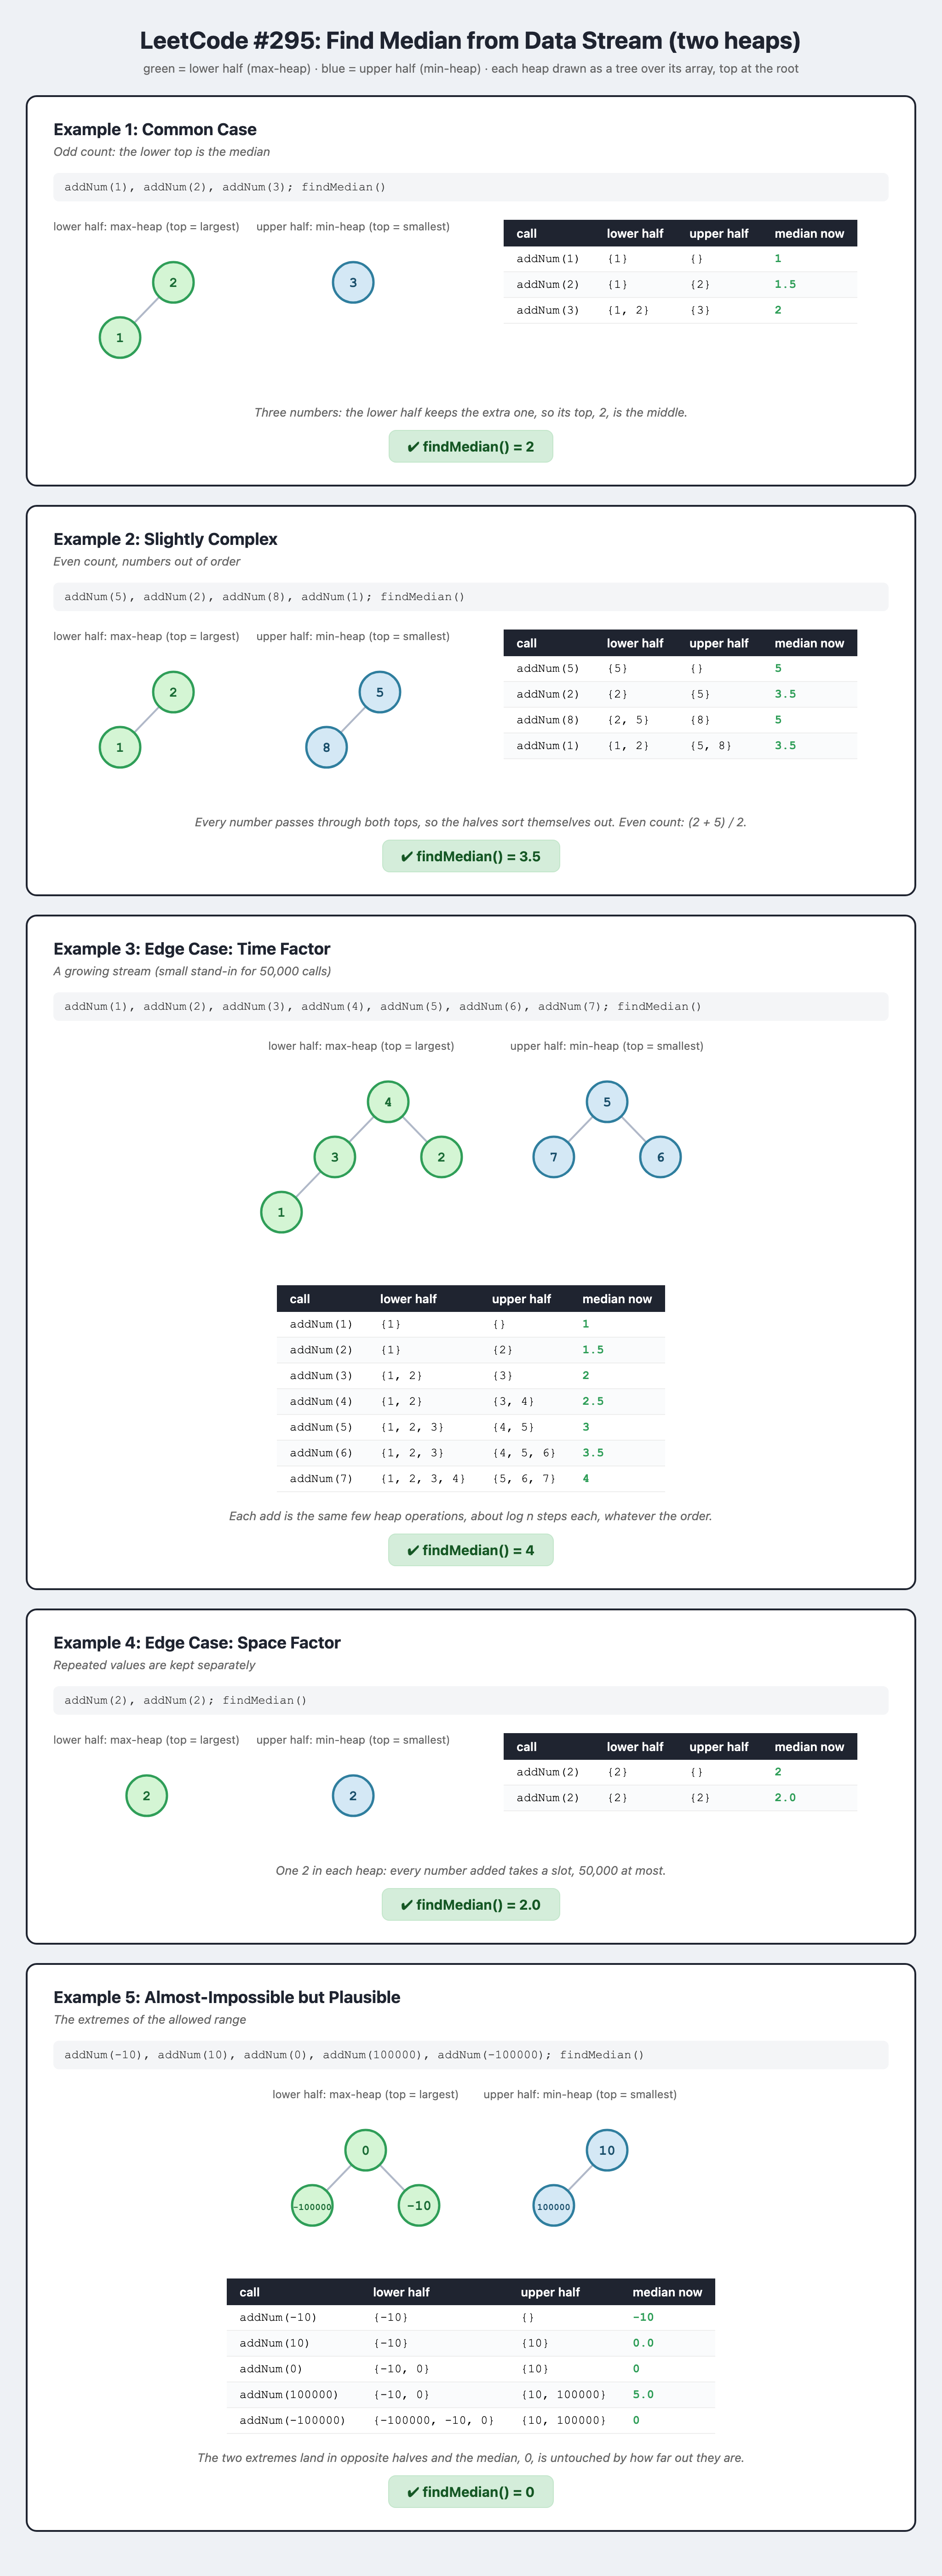

## Watch It Run

*Watch addNum(3): 3 goes into the lower heap, crosses straight to the upper heap as its biggest number, and then 2 comes back down to keep the halves balanced.*

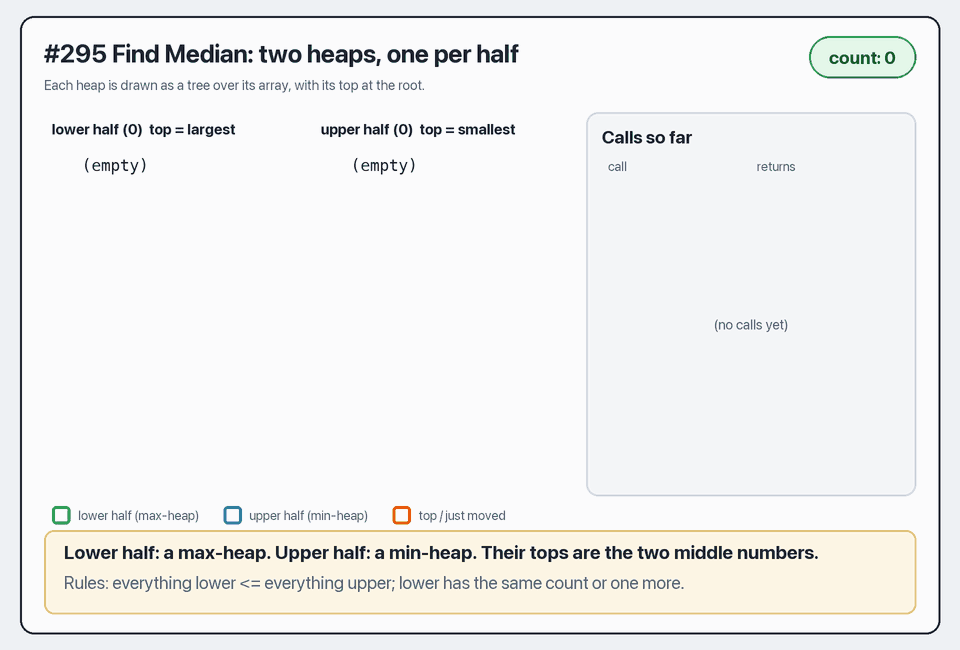